# 📧 Email Intelligence System
**From raw text to understanding: Tokenization → Embeddings → LSTM → Transformer**

```
Raw Email → Tokenization → Embeddings → RNN/LSTM → Transformer → Email Intelligence
                                                                  (Intent + Sentiment + Priority + Action)
```

| Step | What you'll see |
|---|---|
| 1. Data + EDA | Real emails from Kaggle (Enron-derived spam/ham set) |
| 2. Tokenization | Word-level tokens vs. Transformer sub-word tokens |
| 3. Embeddings | Tokens → vectors, and a 2-D map of what the model learned |
| 4. Classification baseline | TF-IDF + Logistic Regression (ignores word order) |
| 5. Sequence modeling | Why order matters + a Bi-LSTM classifier |
| 6. Transformers | Contextual embeddings + fine-tuned DistilBERT, compared with the LSTM |
| 7. Email Intelligence | `analyze_email(text)` → Intent + Sentiment + Priority + Recommended Action |

**Runtime:** ~5–10 min on CPU, ~2 min on a GPU (Colab/Kaggle). Models are downloaded on first run.

In [1]:
# Run once. (In Colab/Kaggle most of these are already installed.)
%pip install -q kagglehub torch transformers scikit-learn pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, glob, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

Using device: cpu


## 1. Data + minimal EDA
We use the Kaggle dataset **`venky73/spam-mails-dataset`** (~5k emails labelled `ham`/`spam`; the legitimate emails are real Enron business emails).
The notebook reads it from your local folder (`LOCAL_DATA_DIR` in the next cell) and falls back to KaggleHub if that folder isn't found.
This gives us a *supervised* task to train and compare models on. Intent, sentiment and priority (Section 7) come from pretrained models + simple rules, because no free Kaggle set has all those labels together.

In [3]:
# Where is the data? Point this at your local folder. If it doesn't exist, we fall back to KaggleHub.
LOCAL_DATA_DIR = r"C:\Users\Swagat\Downloads\SpamMail"

if os.path.isdir(LOCAL_DATA_DIR):
    path = LOCAL_DATA_DIR
    print("Using local folder:", path)
else:
    import kagglehub
    path = kagglehub.dataset_download("venky73/spam-mails-dataset")
    print("Local folder not found - downloaded from Kaggle to:", path)

# The dataset may be a CSV (label,text) or the raw enron-1 layout (ham/ and spam/ folders of .txt files).
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
if csv_files:
    df = pd.read_csv(csv_files[0])
    print("Loaded CSV:", csv_files[0])
    print("Columns:", list(df.columns))
    df = df.rename(columns={"v1": "label", "v2": "text"})        # alt. column names used by some spam sets
    assert {"label", "text"}.issubset(df.columns), "Expected 'label' and 'text' columns - see the printed columns above."
else:
    rows = []
    for lab in ["ham", "spam"]:
        for f in glob.glob(os.path.join(path, "**", lab, "*.txt"), recursive=True):
            with open(f, encoding="latin-1") as fh:
                rows.append((lab, fh.read()))
    assert rows, f"No CSV or ham/spam .txt files found under {path} - check the folder path."
    df = pd.DataFrame(rows, columns=["label", "text"])
    print(f"Loaded {len(df)} .txt emails from ham/ and spam/ folders")

df["label"] = df["label"].astype(str).str.lower().str.strip()
df = df[["label", "text"]].dropna().drop_duplicates(subset="text").reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)      # 0 = ham, 1 = spam
df.head()

Using local folder: C:\Users\Swagat\Downloads\SpamMail
Loaded CSV: C:\Users\Swagat\Downloads\SpamMail\spam_ham_dataset.csv
Columns: ['Unnamed: 0', 'label', 'text', 'label_num']


,label,text,y
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0


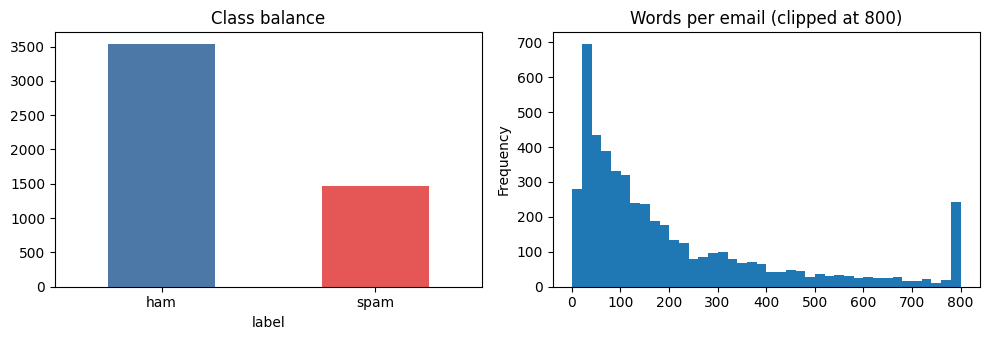

--- Example HAM ---
Subject: enron methanol ; meter # : 988291
this is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary
flow data provided by daren } .
please override pop ' s daily volume { presently zero } to reflect daily
activity you can obtain from gas control .
this change is needed asap for economics purposes . 

--- Example SPAM ---
Subject: photoshop , windows , office . cheap . main trending
abasements darer prudently fortuitous undergone
lighthearted charm orinoco taster
railroad affluent pornographic cuvier
irvin parkhouse blameworthy chlorophyll
robed diagrammatic fogarty clears bayda
inconveniencing managing represented smartness hashish
academies shareholders unl 



In [4]:
# --- Minimal EDA: class balance, email length, one example of each class
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["label"].value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"], rot=0, title="Class balance")
df["text"].str.split().str.len().clip(upper=800).plot.hist(bins=40, ax=ax[1], title="Words per email (clipped at 800)")
plt.tight_layout(); plt.show()

for lab in ["ham", "spam"]:
    print(f"--- Example {lab.upper()} ---")
    print(df[df.label == lab].text.iloc[0][:350].replace("\r", ""), "\n")

## 2. Preprocessing + train / validation / test split
We keep **two versions** of each email:
* `clean` – lowercased, URLs/addresses replaced by placeholders (for the TF-IDF and LSTM models).
* `text` – the untouched original (Transformers have their own tokenizer and like natural casing).

Split: **70% train / 15% validation / 15% test**, stratified so each split keeps the same spam ratio.

In [5]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"^subject:\s*", "", t)             # drop the header word
    t = re.sub(r"https?://\S+|www\.\S+", " url ", t)   # links -> placeholder
    t = re.sub(r"\S+@\S+", " emailaddr ", t)       # addresses -> placeholder
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["clean"] = df["text"].apply(clean_text)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.y, random_state=SEED)
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
print("spam share per split:", [round(d.y.mean(), 3) for d in (train_df, val_df, test_df)])

train=3495  val=749  test=749
spam share per split: [0.293, 0.294, 0.292]


## 3. Tokenization – splitting raw text into tokens
Models can't read text; they read **numbers**. Step one is chopping text into *tokens* and giving each a numeric ID.

Two styles:
1. **Word-level (our own tokenizer)** – simple, but any word not in our vocabulary becomes `<UNK>`.
2. **Sub-word / WordPiece (what Transformers use)** – unknown words are split into known pieces, so nothing is lost.

In [6]:
def tokenize(text):
    # words, numbers, and single punctuation marks become separate tokens
    return re.findall(r"[a-z]+|\d+|[^\sa-z\d]", text.lower())

sample = train_df[train_df.y == 0].clean.iloc[0][:200]
print("RAW      :", sample)
print("TOKENS   :", tokenize(sample))

# Build a vocabulary from TRAIN ONLY (never peek at val/test)
from collections import Counter
counts = Counter(tok for t in train_df.clean for tok in tokenize(t))
PAD, UNK = 0, 1
itos = ["<PAD>", "<UNK>"] + [w for w, c in counts.most_common(20000) if c >= 2]
vocab = {w: i for i, w in enumerate(itos)}
print(f"\nVocabulary size: {len(vocab)}")
print("TOKEN IDS:", [vocab.get(t, UNK) for t in tokenize(sample)])

RAW      : xms - new system effective : we have a new system to prepare expense reports called : expense reporting system : xms in order for us ( your assistants ) to prepare your expense reports you will need t
TOKENS   : ['xms', '-', 'new', 'system', 'effective', ':', 'we', 'have', 'a', 'new', 'system', 'to', 'prepare', 'expense', 'reports', 'called', ':', 'expense', 'reporting', 'system', ':', 'xms', 'in', 'order', 'for', 'us', '(', 'your', 'assistants', ')', 'to', 'prepare', 'your', 'expense', 'reports', 'you', 'will', 'need', 't']

Vocabulary size: 18419
TOKEN IDS: [6215, 2, 96, 218, 247, 7, 33, 38, 14, 96, 218, 8, 2197, 1344, 1137, 823, 7, 1344, 1478, 218, 7, 6215, 17, 250, 12, 135, 27, 37, 6216, 26, 8, 2197, 37, 1344, 1137, 16, 36, 94, 95]


In [7]:
# Sub-word tokenization used by Transformers (DistilBERT's WordPiece)
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification, pipeline
hf_tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

weird = "Claim your freeeemoney now!! Unsubscribe-nowww"
print("Word-level :", tokenize(weird))
print("WordPiece  :", hf_tok.tokenize(weird))
print("\n'##' marks a piece that continues the previous one - unseen words are split, not lost as <UNK>.")

Word-level : ['claim', 'your', 'freeeemoney', 'now', '!', '!', 'unsubscribe', '-', 'nowww']
WordPiece  : ['claim', 'your', 'free', '##eem', '##oney', 'now', '!', '!', 'un', '##su', '##bs', '##cr', '##ibe', '-', 'now', '##w', '##w']

'##' marks a piece that continues the previous one - unseen words are split, not lost as <UNK>.


## 4. Embeddings – turning token IDs into meaningful vectors
An ID like `5231` carries no meaning. An **embedding** maps each ID to a dense vector (e.g. 64 numbers). During training the vectors move so that words used in similar ways end up *close together*.

Below, an untrained `nn.Embedding` just gives random vectors. We'll visualize the **trained** ones after the LSTM in Section 6.

In [8]:
demo_emb = nn.Embedding(len(vocab), 8)       # vocab_size x 8 lookup table
ids = torch.tensor([vocab.get(t, UNK) for t in tokenize("free money now")])
print("Token IDs :", ids.tolist())
print("Embedding shape:", tuple(demo_emb(ids).shape), "-> (3 tokens, 8 dimensions)")
print(demo_emb(ids)[0].detach().numpy().round(2), " <- random for now; training will shape it")

Token IDs : [246, 331, 169]
Embedding shape: (3, 8) -> (3 tokens, 8 dimensions)
[ 0.91 -1.39 -0.71  0.93 -0.42 -0.48  0.48 -0.18]  <- random for now; training will shape it


## 5. Text classification baseline – TF-IDF + Logistic Regression
A "bag of words" model counts words and **ignores their order**. It's fast and a surprisingly strong baseline for spam.

TF-IDF + LogReg: accuracy=0.976  spam-F1=0.959

              precision    recall  f1-score   support

         ham      0.981     0.985     0.983       530
        spam      0.963     0.954     0.959       219

    accuracy                          0.976       749
   macro avg      0.972     0.970     0.971       749
weighted avg      0.976     0.976     0.976       749



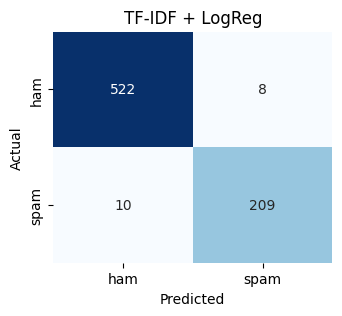

In [9]:
results = {}   # model name -> (accuracy, spam-F1) on the TEST set

def evaluate(name, y_true, y_pred):
    acc, f1 = accuracy_score(y_true, y_pred), f1_score(y_true, y_pred)
    results[name] = (acc, f1)
    print(f"{name}: accuracy={acc:.3f}  spam-F1={f1:.3f}\n")
    print(classification_report(y_true, y_pred, target_names=["ham", "spam"], digits=3))
    plt.figure(figsize=(3.6, 3))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(name); plt.show()

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)
Xtr = tfidf.fit_transform(train_df.clean)
lr = LogisticRegression(max_iter=1000).fit(Xtr, train_df.y)
evaluate("TF-IDF + LogReg", test_df.y, lr.predict(tfidf.transform(test_df.clean)))

## 6. Sequence modeling – why word order matters
Bag-of-words sees these two sentences as *identical*:

In [10]:
a, b = "the manager approved my request", "my manager request approved the"
cv = CountVectorizer().fit([a, b])
print("Same bag-of-words vector? ->", (cv.transform([a]).toarray() == cv.transform([b]).toarray()).all())
print("\nAnother example: 'not good' vs 'good, not bad' share words but mean opposite things.")

Same bag-of-words vector? -> True

Another example: 'not good' vs 'good, not bad' share words but mean opposite things.


An **RNN/LSTM** reads tokens *one after another* and keeps a running memory (hidden state), so earlier words can influence how later words are understood.
We use a **bidirectional LSTM** (reads left→right *and* right→left) and feed its final states to a small classifier.

```
tokens → Embedding → Bi-LSTM → [final forward ⊕ backward state] → Linear → ham / spam
```

In [11]:
MAX_LEN = 200   # truncate/pad every email to this many tokens

def encode(text):
    ids = [vocab.get(t, UNK) for t in tokenize(text)][:MAX_LEN] or [UNK]
    n = len(ids)
    return ids + [PAD] * (MAX_LEN - n), n        # padded ids, true length

def encode_many(texts):
    pairs = [encode(t) for t in texts]
    return torch.tensor([p[0] for p in pairs]), torch.tensor([p[1] for p in pairs])

Xtr_s, Ltr = encode_many(train_df.clean); ytr = torch.tensor(train_df.y.values)
Xva_s, Lva = encode_many(val_df.clean);   yva = torch.tensor(val_df.y.values)
Xte_s, Lte = encode_many(test_df.clean);  yte = torch.tensor(test_df.y.values)

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, hidden=64):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc   = nn.Linear(hidden * 2, 2)

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        # "pack" so the LSTM ignores the <PAD> positions
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], dim=1)      # last forward + last backward state
        return self.fc(self.drop(h))

lstm = LSTMClassifier(len(vocab)).to(DEVICE)
print(f"Trainable parameters: {sum(p.numel() for p in lstm.parameters()):,}")

Trainable parameters: 1,245,634


In [ ]:
from torch.utils.data import DataLoader, TensorDataset

train_loader = DataLoader(TensorDataset(Xtr_s, Ltr, ytr), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xva_s, Lva, yva), batch_size=256)
opt, loss_fn = torch.optim.Adam(lstm.parameters(), lr=2e-3), nn.CrossEntropyLoss()

def run_epoch(loader, train):
    lstm.train(train); loss_sum = correct = n = 0
    for xb, lb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE).long()   # <-- .long() fixes "Long but found Int"
        with torch.set_grad_enabled(train):
            logits = lstm(xb, lb); loss = loss_fn(logits, yb)
        if train:
            opt.zero_grad(); loss.backward(); opt.step()
        loss_sum += loss.item() * len(yb); correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
    return loss_sum / n, correct / n

history, best_val, best_state = [], 0, None
for epoch in range(1, 9):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    history.append((tr_loss, va_loss))
    if va_acc > best_val:
        best_val, best_state = va_acc, {k: v.clone() for k, v in lstm.state_dict().items()}
    print(f"epoch {epoch}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

lstm.load_state_dict(best_state)       # keep the best epoch (by validation accuracy)
plt.plot([h[0] for h in history], label="train"); plt.plot([h[1] for h in history], label="val")
plt.title("LSTM loss"); plt.xlabel("epoch"); plt.legend(); plt.show()

RuntimeError: expected scalar type Long but found Int

In [ ]:
def lstm_predict_proba(texts):
    X, L = encode_many([clean_text(t) for t in texts])
    lstm.eval()
    with torch.no_grad():
        return torch.softmax(lstm(X.to(DEVICE), L), dim=1).cpu().numpy()

evaluate("Bi-LSTM", test_df.y, lstm_predict_proba(test_df.text.tolist()).argmax(1))

### 👀 What did the embeddings learn?
Below: the 100 most common words, projected from 64 → 2 dimensions with PCA. **Red** = appears mostly in spam, **blue** = mostly in legitimate email. Words used in similar contexts drift together.

In [ ]:
spam_c = Counter(tok for t in train_df[train_df.y == 1].clean for tok in tokenize(t))
ham_c  = Counter(tok for t in train_df[train_df.y == 0].clean for tok in tokenize(t))
words = [w for w in itos[2:] if len(w) > 2][:100]                   # itos is sorted by frequency
vecs  = lstm.emb.weight.detach().cpu().numpy()[[vocab[w] for w in words]]
xy    = PCA(n_components=2).fit_transform(vecs)
spam_ratio = np.array([(spam_c[w] + 1) / (spam_c[w] + ham_c[w] + 2) for w in words])

plt.figure(figsize=(9, 6))
plt.scatter(xy[:, 0], xy[:, 1], c=spam_ratio, cmap="coolwarm", s=40)
for (x, y), w in zip(xy, words):
    plt.annotate(w, (x, y), fontsize=8, alpha=0.8)
plt.title("Learned word embeddings (PCA)  -  red = spam-ish, blue = business-ish"); plt.show()

## 7. Bridging to Transformers
**Problem with static embeddings + LSTM:** each word has *one* vector, no matter the sentence ("bank" always means the same thing), and the LSTM must squeeze everything through a sequential memory that fades over long emails.

**Transformers** fix this with **self-attention**: every token looks at *every other token* at once and builds a **contextual** embedding. They are also pretrained on huge text corpora, so they arrive already knowing language.

### 7a. Same word, different meaning

In [ ]:
base = AutoModel.from_pretrained("distilbert-base-uncased").eval()

def word_vector(sentence, word):
    enc = hf_tok(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = base(**enc).last_hidden_state[0]
    tokens = hf_tok.convert_ids_to_tokens(enc["input_ids"][0])
    return hidden[tokens.index(word)]

s1 = "Please wire the payment to my bank account today."
s2 = "The bank approved our loan request yesterday."
s3 = "We had a picnic on the bank of the river."
cos = nn.functional.cosine_similarity
print("Static embedding (Word2Vec/our LSTM): 'bank' vs 'bank' similarity = 1.00 always")
print(f"Transformer  money-bank vs loan-bank : {cos(word_vector(s1,'bank'), word_vector(s2,'bank'), dim=0):.2f}")
print(f"Transformer  money-bank vs river-bank: {cos(word_vector(s1,'bank'), word_vector(s3,'bank'), dim=0):.2f}  <- lower: different meaning")

### 7b. Fine-tune a pretrained Transformer on our emails
We fine-tune **DistilBERT** (a small, fast BERT) for the same ham/spam task. To keep it quick we use a 2,000-email subset of the training data for 1 epoch — raise `N_TRAIN` / `EPOCHS` for better results.

In [ ]:
MODEL, N_TRAIN, EPOCHS, BS, TR_MAXLEN = "distilbert-base-uncased", 2000, 1, 16, 128

clf = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2).to(DEVICE)
sub = train_df.sample(min(N_TRAIN, len(train_df)), random_state=SEED)
texts, labels = sub.text.tolist(), sub.y.tolist()
opt_t = torch.optim.AdamW(clf.parameters(), lr=5e-5)

clf.train()
for epoch in range(EPOCHS):
    order = np.random.permutation(len(texts))
    for step, i in enumerate(range(0, len(order), BS)):
        idx = order[i:i + BS]
        enc = hf_tok([texts[j] for j in idx], truncation=True, max_length=TR_MAXLEN,
                     padding=True, return_tensors="pt").to(DEVICE)
        out = clf(**enc, labels=torch.tensor([labels[j] for j in idx]).to(DEVICE))
        opt_t.zero_grad(); out.loss.backward(); opt_t.step()
        if step % 25 == 0:
            print(f"epoch {epoch+1} step {step:3d}  loss {out.loss.item():.4f}")

def transformer_predict_proba(texts, bs=32):
    clf.eval(); probs = []
    for i in range(0, len(texts), bs):
        enc = hf_tok(list(texts[i:i + bs]), truncation=True, max_length=TR_MAXLEN,
                     padding=True, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            probs.append(torch.softmax(clf(**enc).logits, dim=-1).cpu().numpy())
    return np.vstack(probs)

evaluate("DistilBERT (fine-tuned)", test_df.y, transformer_predict_proba(test_df.text.tolist()).argmax(1))

### 7c. Side-by-side comparison

In [ ]:
comp = pd.DataFrame(results, index=["Accuracy", "Spam F1"]).T
display(comp.round(3))
comp.plot.bar(rot=15, figsize=(7, 3.5), ylim=(comp.values.min() - 0.05, 1.0), title="Test-set comparison")
plt.tight_layout(); plt.show()

**How to read this:**
* Spam vs. ham is an *easy* task (distinctive words like "free", "viagra", "click"), so **all three models score high** and gaps are small. Don't over-interpret a 1% difference.
* The Transformer's real advantage appears on **nuanced language** — sentiment, sarcasm, negation, intent — where meaning depends on context. That's exactly what we need next, so Section 8 uses pretrained Transformers for sentiment and intent.
* Why Transformers win on context: (1) **self-attention** links any two words directly, even far apart; (2) **contextual embeddings** — "bank" gets a different vector per sentence; (3) **pretraining** on billions of words means little labelled data is needed; (4) **sub-word tokens** handle typos and rare words; (5) they process all tokens in **parallel**, unlike an LSTM's step-by-step loop.

## 8. Email Intelligence – putting it all together
| Output | How it is produced |
|---|---|
| **Category** (ham/spam) | Our fine-tuned DistilBERT (+ the LSTM's opinion for comparison) |
| **Intent** | Pretrained **zero-shot** Transformer (NLI model): scores the email against label descriptions with no training |
| **Sentiment** | Pretrained DistilBERT fine-tuned on SST-2 (positive/negative; low confidence → *neutral*) |
| **Priority** | Transparent rules: urgency words, deadlines, intent, negative tone |
| **Recommended action** | Lookup from intent + priority |

In [ ]:
sentiment_pipe = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english",
                          device=0 if DEVICE == "cuda" else -1)
intent_pipe = pipeline("zero-shot-classification", model="typeform/distilbert-base-uncased-mnli",
                       device=0 if DEVICE == "cuda" else -1)

INTENTS = ["request for action", "meeting or scheduling", "question", "complaint or problem",
           "information update", "sales or promotion"]

URGENT_RE   = re.compile(r"\b(urgent|asap|immediately|right away|critical|emergency|overdue|deadline|as soon as possible|eod|end of day)\b", re.I)
TIME_RE     = re.compile(r"\b(today|tonight|tomorrow|this week|by (mon|tues|wednes|thurs|fri)day)\b", re.I)
ACTION_BASE = {
    "request for action":    "Do or delegate the requested task and confirm back",
    "meeting or scheduling": "Check your calendar and accept / propose a time",
    "question":              "Write a direct answer or forward to the right person",
    "complaint or problem":  "Acknowledge the issue and start fixing it",
    "information update":    "Read and file; no reply needed unless something is wrong",
    "sales or promotion":    "Unsubscribe or archive",
}
SLA = {"High": "Respond within hours", "Medium": "Respond within 1-2 days", "Low": "Handle when convenient"}

def compute_priority(text, intent, sentiment, neg_conf):
    score, reasons = 0, []
    if URGENT_RE.search(text):
        score += 2; reasons.append("urgent wording")
    if TIME_RE.search(text):
        score += 1; reasons.append("time-bound")
    if intent in ("request for action", "complaint or problem", "meeting or scheduling"):
        score += 1; reasons.append(f"intent: {intent}")
    if sentiment == "NEGATIVE" and neg_conf > 0.9:
        score += 1; reasons.append("strongly negative tone")
    return ("High" if score >= 3 else "Medium" if score >= 1 else "Low"), reasons

def analyze_email(raw_email):
    """Paste any email text -> returns (and prints) Intent + Sentiment + Priority + Recommended Action."""
    text = raw_email.strip()
    if not text:
        raise ValueError("Empty email.")

    # 1) Category: fine-tuned Transformer (LSTM shown for comparison)
    p_tr, p_lstm = transformer_predict_proba([text])[0], lstm_predict_proba([text])[0]
    is_spam = p_tr[1] > 0.5

    # 2) Sentiment
    s = sentiment_pipe(text, truncation=True, max_length=512)[0]
    sentiment = s["label"] if s["score"] >= 0.80 else "NEUTRAL"

    if is_spam:
        intent, priority, reasons = "spam / unsolicited promotion", "Low", ["classified as spam"]
        action = "Move to spam, do not click links or reply"
    else:
        # 3) Intent (zero-shot): compare the email against each candidate label
        z = intent_pipe(text[:1500], candidate_labels=INTENTS, hypothesis_template="This email is a {}.")
        intent = z["labels"][0]
        # 4) Priority + 5) Action
        neg_conf = s["score"] if s["label"] == "NEGATIVE" else 0
        priority, reasons = compute_priority(text, intent, s["label"], neg_conf)
        action = f"{SLA[priority]}: {ACTION_BASE[intent]}"

    result = {"category": "spam" if is_spam else "ham", "intent": intent, "sentiment": sentiment.lower(),
              "priority": priority, "action": action}

    print("=" * 62)
    print(f"Email   : {text[:90].replace(chr(10), ' ')}{'...' if len(text) > 90 else ''}")
    print(f"Category: {result['category']}  (Transformer spam prob {p_tr[1]:.2f} | LSTM {p_lstm[1]:.2f})")
    print(f"Intent  : {intent}")
    print(f"Sentiment: {result['sentiment']}  ({s['score']:.2f})")
    print(f"Priority: {priority}  ({', '.join(reasons) or 'no urgency signals'})")
    print(f"Action  : {action}")
    return result

In [ ]:
examples = [
    "Subject: URGENT - server down\nHi team, the production server has been down since morning and customers are furious. "
    "Please fix this immediately and send me a status update by end of day today.",

    "Subject: Project sync\nHi Sam, could we meet Thursday afternoon to go over the Q3 roadmap? Let me know what time works for you.",

    "Subject: You WON!!!\nCongratulations! Claim your FREE $1000 gift card now. Click here http://win-big.example to unsubscribe or collect!",

    "Subject: Thanks!\nJust wanted to say the workshop was wonderful and the whole team learned a lot. Great job organizing it.",
]
for e in examples:
    analyze_email(e)

### ✍️ Try your own email
Paste any email into the string below and run the cell.

In [ ]:
my_email = """
Subject: Invoice problem
Hello, I was charged twice for last month's subscription and nobody has replied to my previous messages.
This is really frustrating. Please refund the duplicate payment as soon as possible.
"""
_ = analyze_email(my_email)

## 9. Recap & next steps
* **Tokenization** turned text into IDs (word-level) and sub-words (WordPiece).
* **Embeddings** gave tokens a vector meaning; static ones are context-blind, Transformer ones are contextual.
* **Classification** baseline (TF-IDF) is strong but order-blind.
* **LSTM** models word order sequentially; it is a big conceptual step up but is limited on long/nuanced text.
* **Transformers** use attention + pretraining and power the sentiment and intent stages of our final system.

**Limitations to be aware of:** priority is rule-based (no priority labels exist in this data); the sentiment model was trained on movie reviews, so business-email tone can be off; the zero-shot intent labels are editable in `INTENTS`.
**Ideas to extend:** fine-tune on your own labelled emails, raise `N_TRAIN`/`EPOCHS`, try `TR_MAXLEN=256`, or swap in a larger zero-shot model for better intent accuracy.